In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

In [62]:
df = pd.read_csv(
    'household_power_consumption.txt.txt',
    sep=';',
    na_values='?',
    low_memory=False
)

In [63]:
df.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [64]:
df.shape

(2075259, 9)

In [65]:
df.duplicated().sum()

0

In [66]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   str    
 1   Time                   str    
 2   Global_active_power    float64
 3   Global_reactive_power  float64
 4   Voltage                float64
 5   Global_intensity       float64
 6   Sub_metering_1         float64
 7   Sub_metering_2         float64
 8   Sub_metering_3         float64
dtypes: float64(7), str(2)
memory usage: 176.0 MB


In [67]:
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({
    'Missing Count': missing,
    'Percentage': missing_pct
})

In [68]:
print(missing_df[missing_df['Missing Count'] > 0])

                       Missing Count  Percentage
Global_active_power            25979    1.251844
Global_reactive_power          25979    1.251844
Voltage                        25979    1.251844
Global_intensity               25979    1.251844
Sub_metering_1                 25979    1.251844
Sub_metering_2                 25979    1.251844
Sub_metering_3                 25979    1.251844


In [69]:
df['timestamp'] = pd.to_datetime(df['Date'] + ' ' + df['Time'], 
                                  format='%d/%m/%Y %H:%M:%S')
print("Timestamp created!")

Timestamp created!


In [70]:
df['year'] = df['timestamp'].dt.year
df['month'] = df['timestamp'].dt.month
df['day'] = df['timestamp'].dt.day
df['hour'] = df['timestamp'].dt.hour
df['day_of_week'] = df['timestamp'].dt.dayofweek
df['is_weekend'] = df['day_of_week'].isin([5, 6]).astype(int)

In [71]:
print(f" Date Range: {df['timestamp'].min()} to {df['timestamp'].max()}")
print(f" Duration: {(df['timestamp'].max() - df['timestamp'].min()).days} days")

 Date Range: 2006-12-16 17:24:00 to 2010-11-26 21:02:00
 Duration: 1441 days


In [72]:
print("\n Handling missing values...")
df_clean = df.ffill()
print(f"Missing values handled. Remaining: {df_clean.isnull().sum().sum()}")


 Handling missing values...
Missing values handled. Remaining: 0


In [73]:
print("\n Power Consumption Statistics:")
stats = df_clean['Global_active_power'].describe()
print(stats)


 Power Consumption Statistics:
count    2.075259e+06
mean     1.086168e+00
std      1.053172e+00
min      7.600000e-02
25%      3.080000e-01
50%      5.980000e-01
75%      1.524000e+00
max      1.112200e+01
Name: Global_active_power, dtype: float64


In [74]:
print(f"\n Key Metrics:")
print(f"    Mean: {df_clean['Global_active_power'].mean():.3f} kW")
print(f"    Median: {df_clean['Global_active_power'].median():.3f} kW")
print(f"    Std Dev: {df_clean['Global_active_power'].std():.3f} kW")
print(f"    Peak: {df_clean['Global_active_power'].max():.3f} kW")
print(f"    Minimum: {df_clean['Global_active_power'].min():.3f} kW")


 Key Metrics:
    Mean: 1.086 kW
    Median: 0.598 kW
    Std Dev: 1.053 kW
    Peak: 11.122 kW
    Minimum: 0.076 kW


In [75]:
print("\n Average Consumption by Hour:")
hourly_pattern = df_clean.groupby('hour')['Global_active_power'].mean()
print(hourly_pattern)


 Average Consumption by Hour:
hour
0     0.659583
1     0.540739
2     0.482724
3     0.447379
4     0.446164
5     0.455703
6     0.788972
7     1.490076
8     1.449551
9     1.322167
10    1.252229
11    1.237853
12    1.199247
13    1.137712
14    1.077447
15    0.987055
16    0.945568
17    1.050723
18    1.317963
19    1.721268
20    1.886522
21    1.865132
22    1.405145
23    0.899950
Name: Global_active_power, dtype: float64


In [76]:
print("\n Peak Hours:")
print(hourly_pattern.nlargest(5))


 Peak Hours:
hour
20    1.886522
21    1.865132
19    1.721268
7     1.490076
8     1.449551
Name: Global_active_power, dtype: float64


In [77]:
print("\n Low Usage Hours:")
print(hourly_pattern.nsmallest(5))


 Low Usage Hours:
hour
4    0.446164
3    0.447379
5    0.455703
2    0.482724
1    0.540739
Name: Global_active_power, dtype: float64


In [78]:
weekday_avg = df_clean[df_clean['is_weekend'] == 0]['Global_active_power'].mean()
weekend_avg = df_clean[df_clean['is_weekend'] == 1]['Global_active_power'].mean()

In [79]:
print(f"\n Weekday vs Weekend:")
print(f"    Weekday Average: {weekday_avg:.3f} kW")
print(f"    Weekend Average: {weekend_avg:.3f} kW")
print(f"    Difference: {abs(weekday_avg - weekend_avg):.3f} kW ({((weekend_avg/weekday_avg - 1)*100):.1f}%)")


 Weekday vs Weekend:
    Weekday Average: 1.034 kW
    Weekend Average: 1.217 kW
    Difference: 0.183 kW (17.7%)


In [80]:
mean_power = df_clean['Global_active_power'].mean()
std_power = df_clean['Global_active_power'].std()
threshold_high = mean_power + (3 * std_power)
threshold_low = mean_power - (3 * std_power)

In [81]:
anomalies_high = df_clean[df_clean['Global_active_power'] > threshold_high]
anomalies_low = df_clean[(df_clean['Global_active_power'] < threshold_low) & 
                         (df_clean['Global_active_power'] > 0)]

In [82]:
print(f"Anomaly Detection Results:")
print(f"    High consumption anomalies: {len(anomalies_high):,} ({(len(anomalies_high)/len(df_clean)*100):.2f}%)")
print(f"    Low consumption anomalies: {len(anomalies_low):,} ({(len(anomalies_low)/len(df_clean)*100):.2f}%)")
print(f"    Threshold High: {threshold_high:.3f} kW")
print(f"    Threshold Low: {threshold_low:.3f} kW")

Anomaly Detection Results:
    High consumption anomalies: 36,803 (1.77%)
    Low consumption anomalies: 0 (0.00%)
    Threshold High: 4.246 kW
    Threshold Low: -2.073 kW


In [83]:
if len(anomalies_high) > 0:
    print(f"\nTop 5 High Consumption Anomalies:")
    top_anomalies = anomalies_high.nlargest(5, 'Global_active_power')[
        ['timestamp', 'Global_active_power', 'hour', 'day_of_week']
    ]
    print(top_anomalies.to_string())


Top 5 High Consumption Anomalies:
                  timestamp  Global_active_power  hour  day_of_week
1150545 2009-02-22 17:09:00               11.122    17            6
112450  2007-03-04 19:34:00               10.670    19            6
112449  2007-03-04 19:33:00               10.650    19            6
1150544 2009-02-22 17:08:00               10.536    17            6
1029775 2008-11-30 20:19:00               10.348    20            6


In [84]:
print("\n Average Energy by Appliance Category:")
print(f"    Kitchen (Sub_metering_1): {df_clean['Sub_metering_1'].mean():.2f} Wh")
print(f"    Laundry (Sub_metering_2): {df_clean['Sub_metering_2'].mean():.2f} Wh")
print(f"    HVAC (Sub_metering_3): {df_clean['Sub_metering_3'].mean():.2f} Wh")

total_submetering = (df_clean['Sub_metering_1'].mean() + 
                     df_clean['Sub_metering_2'].mean() + 
                     df_clean['Sub_metering_3'].mean())
print(f"    Total Sub-metered: {total_submetering:.2f} Wh")


 Average Energy by Appliance Category:
    Kitchen (Sub_metering_1): 1.11 Wh
    Laundry (Sub_metering_2): 1.29 Wh
    HVAC (Sub_metering_3): 6.42 Wh
    Total Sub-metered: 8.82 Wh


In [85]:
kitchen_pct = (df_clean['Sub_metering_1'].mean() / total_submetering) * 100
laundry_pct = (df_clean['Sub_metering_2'].mean() / total_submetering) * 100
hvac_pct = (df_clean['Sub_metering_3'].mean() / total_submetering) * 100

print(f"\n Percentage Breakdown:")
print(f"    Kitchen: {kitchen_pct:.1f}%")
print(f"    Laundry: {laundry_pct:.1f}%")
print(f"    HVAC: {hvac_pct:.1f}%")


 Percentage Breakdown:
    Kitchen: 12.6%
    Laundry: 14.6%
    HVAC: 72.8%



 Creating Figure 1: Daily consumption trend...


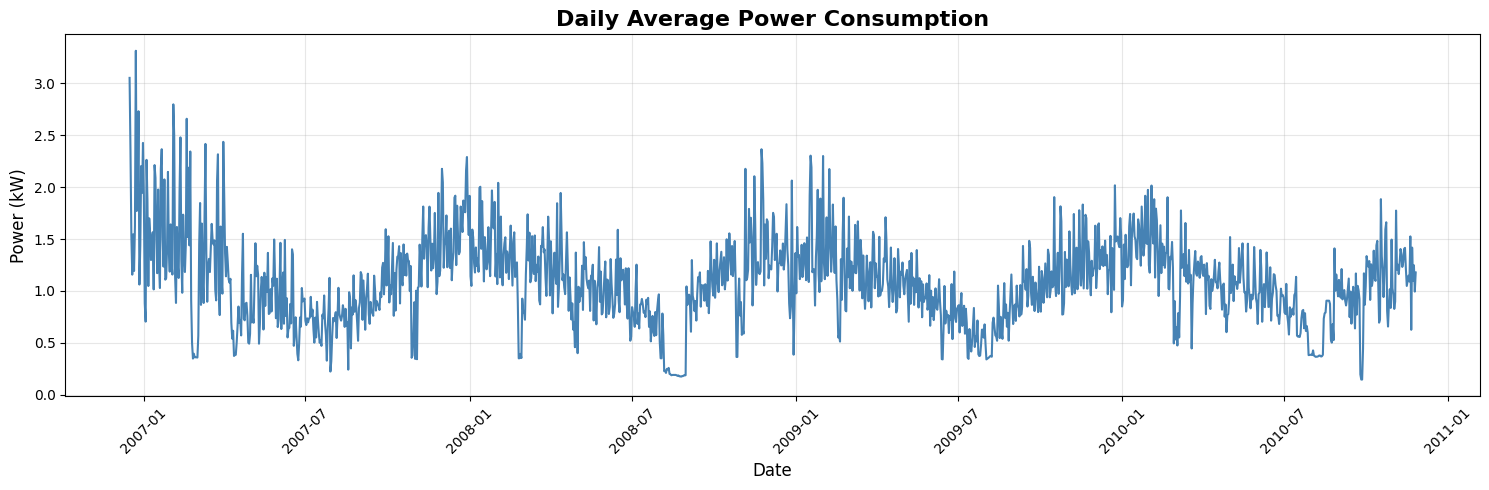

In [86]:
print("\n Creating Figure 1: Daily consumption trend...")
fig, ax = plt.subplots(figsize=(15, 5))
daily_avg = df_clean.groupby(df_clean['timestamp'].dt.date)['Global_active_power'].mean()
ax.plot(daily_avg.index, daily_avg.values, linewidth=1.5, color='steelblue')
ax.set_title('Daily Average Power Consumption', fontsize=16, fontweight='bold')
ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Power (kW)', fontsize=12)
ax.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


 Creating Figure 2: Hourly consumption pattern...


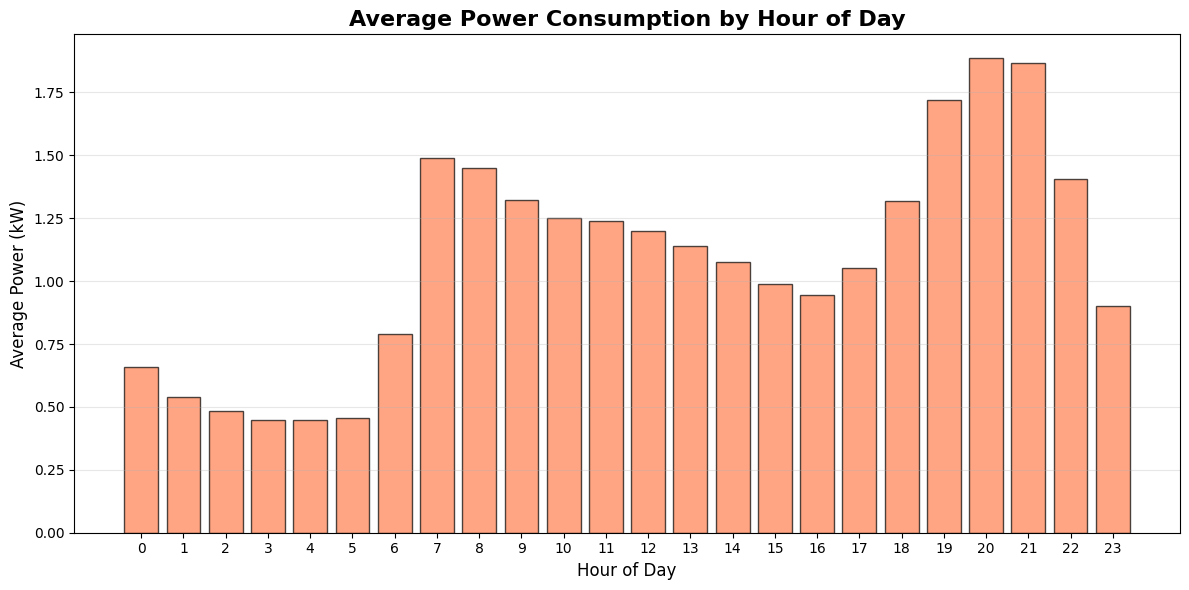

In [87]:
print("\n Creating Figure 2: Hourly consumption pattern...")
fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(hourly_pattern.index, hourly_pattern.values, color='coral', alpha=0.7, edgecolor='black')
ax.set_title('Average Power Consumption by Hour of Day', fontsize=16, fontweight='bold')
ax.set_xlabel('Hour of Day', fontsize=12)
ax.set_ylabel('Average Power (kW)', fontsize=12)
ax.set_xticks(range(24))
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()


 Creating Figure 3: Weekday vs weekend comparison...


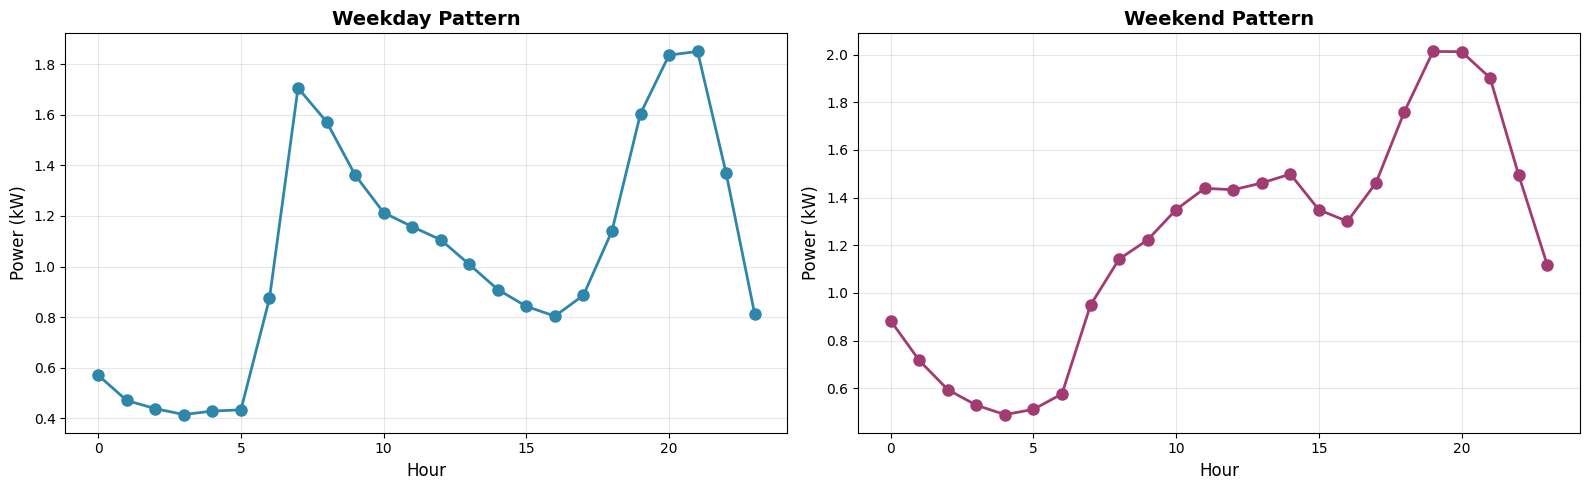

In [88]:
print("\n Creating Figure 3: Weekday vs weekend comparison...")
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

weekday_data = df_clean[df_clean['is_weekend'] == 0]
weekday_hourly = weekday_data.groupby('hour')['Global_active_power'].mean()
axes[0].plot(weekday_hourly.index, weekday_hourly.values, 
             marker='o', linewidth=2, markersize=8, color='#2E86AB')
axes[0].set_title('Weekday Pattern', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Hour', fontsize=12)
axes[0].set_ylabel('Power (kW)', fontsize=12)
axes[0].grid(True, alpha=0.3)

weekend_data = df_clean[df_clean['is_weekend'] == 1]
weekend_hourly = weekend_data.groupby('hour')['Global_active_power'].mean()
axes[1].plot(weekend_hourly.index, weekend_hourly.values, 
             marker='o', linewidth=2, markersize=8, color='#A23B72')
axes[1].set_title('Weekend Pattern', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Hour', fontsize=12)
axes[1].set_ylabel('Power (kW)', fontsize=12)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


 Creating Figure 4: Sub-metering breakdown...


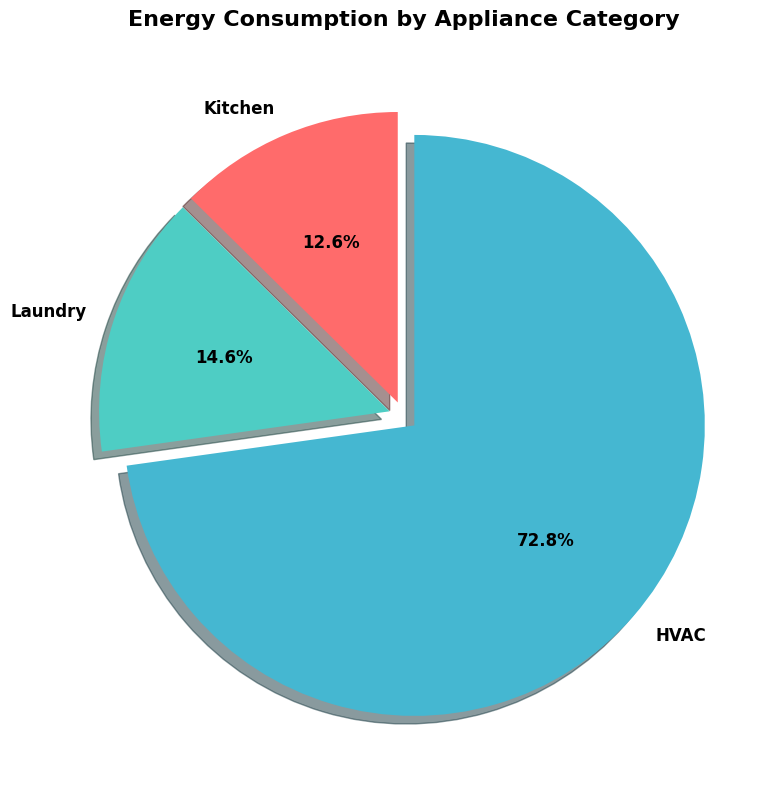

In [89]:
print("\n Creating Figure 4: Sub-metering breakdown...")
fig, ax = plt.subplots(figsize=(10, 8))
labels = ['Kitchen', 'Laundry', 'HVAC']
sizes = [
    df_clean['Sub_metering_1'].mean(),
    df_clean['Sub_metering_2'].mean(),
    df_clean['Sub_metering_3'].mean()
]
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1']
explode = (0.05, 0.05, 0.05)

ax.pie(sizes, explode=explode, labels=labels, colors=colors, autopct='%1.1f%%',
       shadow=True, startangle=90, textprops={'fontsize': 12, 'fontweight': 'bold'})
ax.set_title('Energy Consumption by Appliance Category', fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

In [90]:
features_df = pd.DataFrame()

In [91]:
features_df['global_active_power'] = df_clean['Global_active_power']
features_df['global_reactive_power'] = df_clean['Global_reactive_power']
features_df['voltage'] = df_clean['Voltage']
features_df['global_intensity'] = df_clean['Global_intensity']

In [92]:
features_df['sub_metering_1'] = df_clean['Sub_metering_1']
features_df['sub_metering_2'] = df_clean['Sub_metering_2']
features_df['sub_metering_3'] = df_clean['Sub_metering_3']

In [93]:
features_df['total_submetering'] = (df_clean['Sub_metering_1'] + 
                                     df_clean['Sub_metering_2'] + 
                                     df_clean['Sub_metering_3'])

In [94]:
features_df['unmetered_power'] = (df_clean['Global_active_power'] * 1000 / 60) - features_df['total_submetering']

In [95]:
features_df['hour'] = df_clean['hour']
features_df['is_weekend'] = df_clean['is_weekend']

In [96]:
features_df['power_factor'] = features_df['global_active_power'] / (
    np.sqrt(features_df['global_active_power']**2 + features_df['global_reactive_power']**2) + 1e-6
)

In [97]:
print(f"Created {features_df.shape[1]} features for anomaly detection")
print(f"\nFeatures: {features_df.columns.tolist()}")

Created 12 features for anomaly detection

Features: ['global_active_power', 'global_reactive_power', 'voltage', 'global_intensity', 'sub_metering_1', 'sub_metering_2', 'sub_metering_3', 'total_submetering', 'unmetered_power', 'hour', 'is_weekend', 'power_factor']


In [98]:
model_features = [
    'global_active_power', 'global_reactive_power', 'voltage', 
    'global_intensity', 'total_submetering', 'unmetered_power', 
    'power_factor', 'hour'
]

In [99]:
X = features_df[model_features].copy()

In [100]:
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

In [101]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [102]:
print(f"Training data shape: {X_scaled.shape}")

Training data shape: (2075259, 8)


In [103]:
iso_forest = IsolationForest(
    contamination=0.05,
    random_state=42,
    n_estimators=100,
    max_samples='auto',
    verbose=0
)


In [104]:
print("Training Isolation Forest...")
predictions = iso_forest.fit_predict(X_scaled)

Training Isolation Forest...


In [105]:
anomaly_scores = iso_forest.score_samples(X_scaled)

In [106]:
features_df['anomaly'] = predictions
features_df['anomaly_score'] = anomaly_scores
features_df['timestamp'] = df_clean['timestamp']

In [107]:
features_df['is_anomaly'] = (features_df['anomaly'] == -1).astype(int)

In [108]:
total_anomalies = features_df['is_anomaly'].sum()
anomaly_percentage = (total_anomalies / len(features_df)) * 100

print(f"\n ANOMALY DETECTION SUMMARY:")
print(f"    Total data points: {len(features_df):,}")
print(f"    Anomalies detected: {total_anomalies:,}")
print(f"    Anomaly rate: {anomaly_percentage:.2f}%")


 ANOMALY DETECTION SUMMARY:
    Total data points: 2,075,259
    Anomalies detected: 103,763
    Anomaly rate: 5.00%


In [109]:
anomalies = features_df[features_df['is_anomaly'] == 1].copy()
normal = features_df[features_df['is_anomaly'] == 0].copy()

In [110]:
print(f"\n NORMAL vs ANOMALOUS CONSUMPTION:")
print(f"   Normal - Mean: {normal['global_active_power'].mean():.3f} kW")
print(f"   Anomaly - Mean: {anomalies['global_active_power'].mean():.3f} kW")
print(f"   Difference: {abs(anomalies['global_active_power'].mean() - normal['global_active_power'].mean()):.3f} kW")


 NORMAL vs ANOMALOUS CONSUMPTION:
   Normal - Mean: 0.944 kW
   Anomaly - Mean: 3.782 kW
   Difference: 2.837 kW


In [111]:
high_consumption = anomalies[anomalies['global_active_power'] > normal['global_active_power'].quantile(0.95)]
print(f"    High consumption anomalies: {len(high_consumption):,} ({len(high_consumption)/total_anomalies*100:.1f}%)")

    High consumption anomalies: 85,322 (82.2%)


In [112]:
low_consumption = anomalies[anomalies['global_active_power'] < normal['global_active_power'].quantile(0.05)]
print(f"    Low consumption anomalies: {len(low_consumption):,} ({len(low_consumption)/total_anomalies*100:.1f}%)")

    Low consumption anomalies: 124 (0.1%)


In [113]:
voltage_anomalies = anomalies[
    (anomalies['voltage'] > normal['voltage'].quantile(0.95)) | 
    (anomalies['voltage'] < normal['voltage'].quantile(0.05))
]
print(f"    Voltage anomalies: {len(voltage_anomalies):,} ({len(voltage_anomalies)/total_anomalies*100:.1f}%)")

    Voltage anomalies: 35,915 (34.6%)


In [114]:
theft_indicators = anomalies[anomalies['unmetered_power'] > normal['unmetered_power'].quantile(0.95)]
print(f"    Potential theft indicators: {len(theft_indicators):,} ({len(theft_indicators)/total_anomalies*100:.1f}%)")

    Potential theft indicators: 48,919 (47.1%)


In [115]:
anomalies['hour'] = anomalies['timestamp'].dt.hour
hourly_anomalies = anomalies.groupby('hour').size()

print(f"\n Peak Anomaly Hours:")
print(hourly_anomalies.nlargest(5).to_string())


 Peak Anomaly Hours:
hour
19    12430
20    11159
21     9535
18     6246
22     5621


In [116]:
weekday_anomalies = anomalies[anomalies['is_weekend'] == 0]
weekend_anomalies = anomalies[anomalies['is_weekend'] == 1]

In [117]:
print(f"\n Weekday vs Weekend Anomalies:")
print(f"   • Weekday: {len(weekday_anomalies):,} ({len(weekday_anomalies)/len(anomalies)*100:.1f}%)")
print(f"   • Weekend: {len(weekend_anomalies):,} ({len(weekend_anomalies)/len(anomalies)*100:.1f}%)")



 Weekday vs Weekend Anomalies:
   • Weekday: 58,453 (56.3%)
   • Weekend: 45,310 (43.7%)


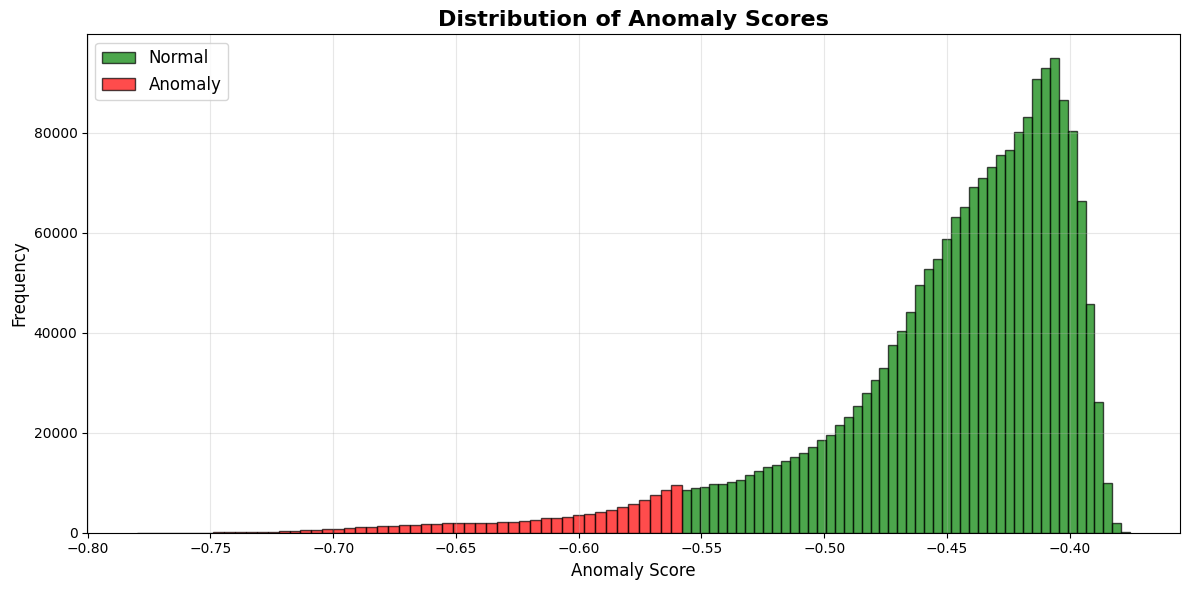

In [118]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.hist(normal['anomaly_score'], bins=50, alpha=0.7, label='Normal', color='green', edgecolor='black')
ax.hist(anomalies['anomaly_score'], bins=50, alpha=0.7, label='Anomaly', color='red', edgecolor='black')
ax.set_xlabel('Anomaly Score', fontsize=12)
ax.set_ylabel('Frequency', fontsize=12)
ax.set_title('Distribution of Anomaly Scores', fontsize=16, fontweight='bold')
ax.legend(fontsize=12)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

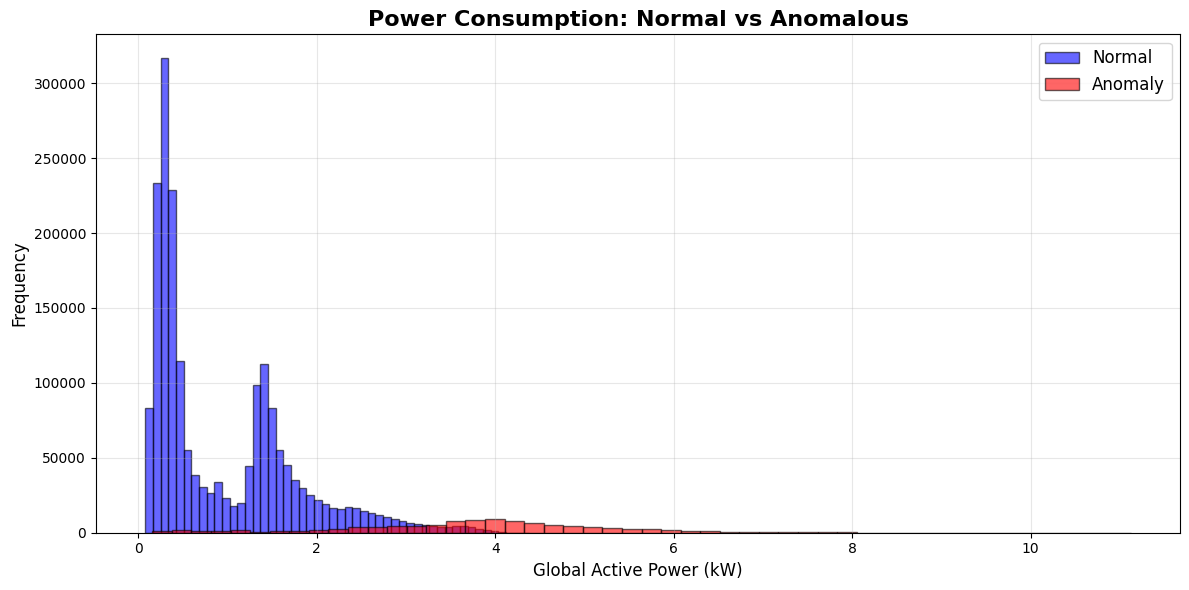

In [119]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.hist(normal['global_active_power'], bins=50, alpha=0.6, label='Normal', color='blue', edgecolor='black')
ax.hist(anomalies['global_active_power'], bins=50, alpha=0.6, label='Anomaly', color='red', edgecolor='black')
ax.set_xlabel('Global Active Power (kW)', fontsize=12)
ax.set_ylabel('Frequency', fontsize=12)
ax.set_title('Power Consumption: Normal vs Anomalous', fontsize=16, fontweight='bold')
ax.legend(fontsize=12)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


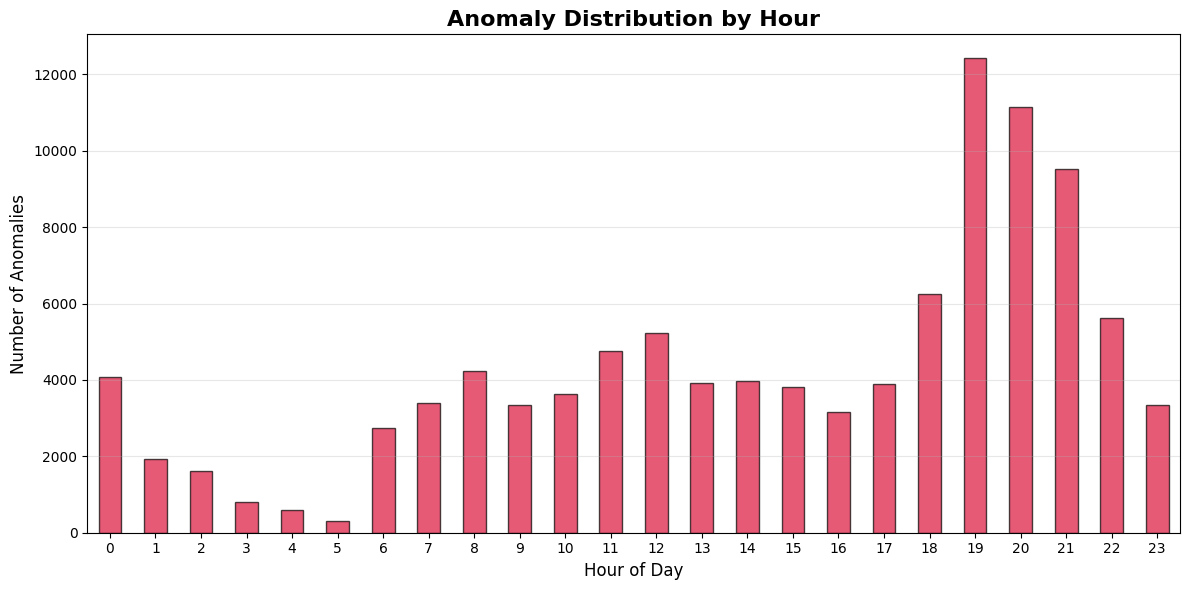

In [120]:
fig, ax = plt.subplots(figsize=(12, 6))
hourly_anomalies.plot(kind='bar', ax=ax, color='crimson', edgecolor='black', alpha=0.7)
ax.set_xlabel('Hour of Day', fontsize=12)
ax.set_ylabel('Number of Anomalies', fontsize=12)
ax.set_title('Anomaly Distribution by Hour', fontsize=16, fontweight='bold')
ax.grid(True, alpha=0.3, axis='y')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()